In [12]:
from pyprojroot import here
import warnings
from pathlib import Path
from typing import Tuple, Dict, List

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from PIL import Image
from tqdm.notebook import tqdm  # notebook-friendly progress bars

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import WeightedRandomSampler
import timm

from monai.data import CacheDataset, DataLoader
from monai.transforms import (
    Compose,
    LoadImaged,
    EnsureChannelFirstd,
    ScaleIntensityd,
    Resized,
    Flipd,
    Rotate90d,
    RandFlipd,
    RandRotate90d,
    RandRotated,
    RandZoomd,
    RandGaussianNoised,
    RandAdjustContrastd,
    RandGaussianSmoothd,
    RandAffined,
    NormalizeIntensityd,
    ToTensord,
    MapTransform,
)
from monai.utils import set_determinism
from monai.config import KeysCollection

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    classification_report,
    confusion_matrix,
    f1_score,
    accuracy_score,
)

warnings.filterwarnings("ignore")

In [13]:
class Config:
    # ==================== Paths ====================
    PARENTS = here()
    DATA_DIR = PARENTS / Path("data")
    LABELS_CSV = DATA_DIR / "Labels.csv"
    IMAGES_DIR = DATA_DIR / "Images"
    OUTPUT_DIR = PARENTS / Path("outputs")

    # ==================== Dataset ====================
    IMG_SIZE = 380
    LABEL_COL = "Label"
    IMAGE_COL = "Image Name"
    PATIENT_COL = "Patient"
    QUALITY_COL = "Quality Score"

    # ==================== Training Params ====================
    SEED = 42
    BATCH_SIZE = 16
    NUM_WORKERS = 4
    EPOCHS = 40
    LR = 3e-4
    WEIGHT_DECAY = 1e-4
    DROPOUT = 0.4
    EARLY_STOP = 8

    # ==================== Augmentation ====================
    USE_MIXUP = True
    MIXUP_ALPHA = 0.2

    # ==================== Model ====================
    BACKBONE = "efficientnet_b3"
    PRETRAINED = True

    # ==================== Inference ====================
    USE_TTA = True
    TTA_STEPS = 5

    # ==================== Classes ====================
    CLASS_NAMES = ["GON-", "GON+"]
    POS_LABEL = "GON+"

    # ==================== MONAI CacheDataset ====================
    CACHE_RATE = 1.0


DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
cfg = Config()
cfg.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
set_determinism(seed=cfg.SEED)

# Print path to make sure it correct
print(f"Project root : {cfg.PARENTS}")
print(f"Labels CSV   : {cfg.LABELS_CSV}")
print(f"Images dir   : {cfg.IMAGES_DIR}")
print(f"Output dir   : {cfg.OUTPUT_DIR}")
print()
print(f"Labels dir exists : {cfg.LABELS_CSV.exists()}")
print(f"Images dir exists : {cfg.IMAGES_DIR.exists()}")


Project root : c:\Users\LMS\Documents\CodeProject\Py\HYGD Dataset
Labels CSV   : c:\Users\LMS\Documents\CodeProject\Py\HYGD Dataset\data\Labels.csv
Images dir   : c:\Users\LMS\Documents\CodeProject\Py\HYGD Dataset\data\Images
Output dir   : c:\Users\LMS\Documents\CodeProject\Py\HYGD Dataset\outputs

Labels dir exists : True
Images dir exists : True


# Load dataset

In [14]:
def load_and_clean_labels(csv_path: Path) -> pd.DataFrame:
    df = pd.read_csv(csv_path)
    print(f"[DATA] Raw: {len(df)} images, {df[cfg.PATIENT_COL].nunique()} patients")
    print(f"Classes:\n{df[cfg.LABEL_COL].value_counts()}\n")

    # binary encoding
    df["label"] = (df[cfg.LABEL_COL] == cfg.POS_LABEL).astype(int)
    df["image_path"] = df[cfg.IMAGE_COL].apply(lambda x: str(cfg.IMAGES_DIR / x))

    # check non-existence file
    missing = [p for p in df["image_path"] if not Path(p).exists()]
    if missing:
        print(f"[WARNING] {len(missing)} image(s) not found. First 3:")
        for p in missing[:3]:
            print(f"{p}")
    else:
        print(f"[DATA] All {len(df)} image paths verified OK.")

    # remove Unnamed column
    df = df.loc[:, ~df.columns.str.contains("^Unnamed")]

    return df


df = load_and_clean_labels(cfg.LABELS_CSV)
df.head()

[DATA] Raw: 747 images, 288 patients
Classes:
Label
GON+    548
GON-    199
Name: count, dtype: int64

[DATA] All 747 image paths verified OK.


,Image Name,Patient,Label,Quality Score,label,image_path
0,0_0.jpg,0,GON+,6.18,1,c:\Users\LMS\Documents\CodeProject\Py\HYGD Dat...
1,1_0.jpg,1,GON+,5.31,1,c:\Users\LMS\Documents\CodeProject\Py\HYGD Dat...
2,1_1.jpg,1,GON+,4.37,1,c:\Users\LMS\Documents\CodeProject\Py\HYGD Dat...
3,2_0.jpg,2,GON+,3.51,1,c:\Users\LMS\Documents\CodeProject\Py\HYGD Dat...
4,2_1.jpg,2,GON+,4.24,1,c:\Users\LMS\Documents\CodeProject\Py\HYGD Dat...


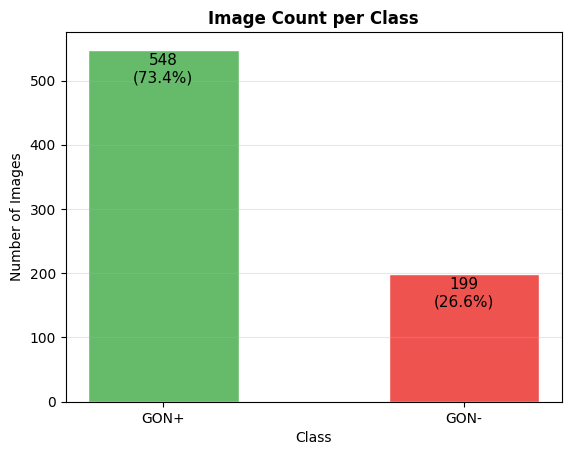

In [15]:
# visualise class distribution
counts = df[cfg.LABEL_COL].value_counts()
colors = ["#66BB6A", "#EF5350"]

# bar chart
bars = plt.bar(counts.index, counts.values, color=colors, edgecolor="white", width=0.5)
for bar, val in zip(bars, counts.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() - 50,
        f"{val}\n({val / len(df) * 100:.1f}%)",
        ha="center",
        fontsize=11,
    )
plt.title("Image Count per Class", fontweight="bold")
plt.ylabel("Number of Images")
plt.xlabel("Class")
plt.grid(axis="y", alpha=0.3)
plt.show()

# MONAI Data format(Dict)

In [16]:
def df_to_monai_list(df: pd.DataFrame) -> List[Dict]:
    return [
        {"image": row["image_path"], "label": int(row["label"])}
        for _, row in df.iterrows()
    ]

# make sure it run properly
sample_list = df_to_monai_list(df)

print(f"Total items : {len(sample_list)}")
print(f"\nFirst item  : {sample_list[0]}")
print(f"Last item   : {sample_list[-1]}")
print(f"\nKeys in each dict: {list(sample_list[0].keys())}")
print(f"Label dtype : {type(sample_list[0]['label'])}")

Total items : 747

First item  : {'image': 'c:\\Users\\LMS\\Documents\\CodeProject\\Py\\HYGD Dataset\\data\\Images\\0_0.jpg', 'label': 1}
Last item   : {'image': 'c:\\Users\\LMS\\Documents\\CodeProject\\Py\\HYGD Dataset\\data\\Images\\288_0.jpg', 'label': 0}

Keys in each dict: ['image', 'label']
Label dtype : <class 'int'>


# Train test split

In [17]:
def patient_stratified_split(
    df: pd.DataFrame,
    val_size: float = 0.15,
    test_size: float = 0.15,
) -> Tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    pat = (
        df.groupby(cfg.PATIENT_COL)["label"]
        .agg(lambda x: int(x.mean() >= 0.5))
        .reset_index()
    )

    p_tr, p_tmp, _, y_tmp = train_test_split(
        pat[cfg.PATIENT_COL].values,
        pat["label"].values,
        test_size=val_size + test_size,
        stratify=pat["label"].values,
        random_state=cfg.SEED,
    )
    p_val, p_test = train_test_split(
        p_tmp, test_size=0.5, stratify=y_tmp, random_state=cfg.SEED
    )

    tr = df[df[cfg.PATIENT_COL].isin(p_tr)].reset_index(drop=True)
    vl = df[df[cfg.PATIENT_COL].isin(p_val)].reset_index(drop=True)
    te = df[df[cfg.PATIENT_COL].isin(p_test)].reset_index(drop=True)

    for name, split in [("Train", tr), ("Val  ", vl), ("Test ", te)]:
        print(
            f"[SPLIT] {name}: {len(split):4d} images | "
            f"{split[cfg.PATIENT_COL].nunique():3d} patients | "
            f"GON+: {split['label'].sum():3d} | "
            f"GON-: {(split['label'] == 0).sum():3d}"
        )
    return tr, vl, te


train_df, val_df, test_df = patient_stratified_split(df)

[SPLIT] Train:  502 images | 201 patients | GON+: 363 | GON-: 139
[SPLIT] Val  :  124 images |  43 patients | GON+:  93 | GON-:  31
[SPLIT] Test :  121 images |  44 patients | GON+:  92 | GON-:  29


Patient overlap check (all should be 0):
- Train ∩ Val: 0 patients
- Train ∩ Test: 0 patients
- Val ∩ Test: 0 patients



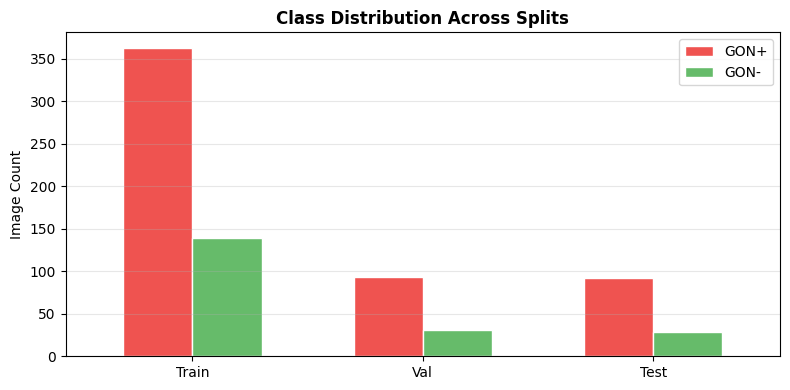

In [18]:
# verify no same patient appears in more than one split
train_patients = set(train_df[cfg.PATIENT_COL])
val_patients = set(val_df[cfg.PATIENT_COL])
test_patients = set(test_df[cfg.PATIENT_COL])

tv_overlap = train_patients & val_patients
tt_overlap = train_patients & test_patients
vt_overlap = val_patients & test_patients

print("Patient overlap check (all should be 0):")
print(f"- Train ∩ Val: {len(tv_overlap)} patients")
print(f"- Train ∩ Test: {len(tt_overlap)} patients")
print(f"- Val ∩ Test: {len(vt_overlap)} patients")
print()

#  visualise split proportions
split_data = {
    "Split": ["Train", "Val", "Test"],
    "GON+": [train_df["label"].sum(), val_df["label"].sum(), test_df["label"].sum()],
    "GON-": [
        (train_df["label"] == 0).sum(),
        (val_df["label"] == 0).sum(),
        (test_df["label"] == 0).sum(),
    ],
}
split_df = pd.DataFrame(split_data).set_index("Split")

ax = split_df.plot(
    kind="bar",
    figsize=(8, 4),
    color=["#EF5350", "#66BB6A"],
    edgecolor="white",
    width=0.6,
)
ax.set_title("Class Distribution Across Splits", fontweight="bold")
ax.set_ylabel("Image Count")
ax.set_xlabel("")
ax.legend(["GON+", "GON-"])
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# MONAI - Other Transformation

In [19]:
class FovMaskd(MapTransform):
    """
    Prevent model to focus on region outside fov by setting the pixel value of the region to 0.

    How it detects the FOV:
      1. Convert to uint8 grayscale
      2. Threshold at a low value to find any non-black pixel
      3. Find the largest contour (the FOV circle)
      4. Draw a filled circle mask from that contour's bounding geometry
      5. Apply the mask — pixels outside = 0.0
    """

    def __init__(self, keys: KeysCollection, threshold: int = 15):
        super().__init__(keys)
        self.threshold = threshold

    def __call__(self, data: dict) -> dict:
        d = dict(data)
        for key in self.keys:
            img = d[key]  # (C, H, W) float32

            # foce numpy datatype
            if hasattr(img, "numpy"):
                arr = img.numpy()
            else:
                arr = np.array(img)

            C, H, W = arr.shape

            # Find FOV contour
            gray = (arr.mean(axis=0) * 255).astype(np.uint8)  # (H, W)
            _, binary = cv2.threshold(gray, self.threshold, 255, cv2.THRESH_BINARY)
            binary = cv2.morphologyEx(
                binary,
                cv2.MORPH_CLOSE,
                kernel=cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15)),
            )
            contours, _ = cv2.findContours(
                binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
            )

            # defining mask
            mask = np.zeros((H, W), dtype=np.uint8)
            if contours:
                largest = max(contours, key=cv2.contourArea)

                # fit a circle to the contour for a clean circular mask
                (cx, cy), radius = cv2.minEnclosingCircle(largest)
                cv2.circle(
                    mask,
                    center=(int(cx), int(cy)),
                    radius=int(radius),
                    color=255,
                    thickness=-1,
                )
            else:
                mask[:] = 255

            # apply mask
            mask_float = (mask / 255.0).astype(np.float32)  # (H, W), values 0 or 1
            arr = arr * mask_float[np.newaxis, :, :]  # broadcast over C

            # preserve original type
            if hasattr(img, "numpy"):
                d[key] = torch.from_numpy(arr)
            else:
                d[key] = arr

        return d

In [ ]:
class CLAHEd(MapTransform):
    def __init__(
        self,
        keys: KeysCollection,
        clip_limit: float = 2.0,
        tile_grid_size: tuple = (8, 8),
    ):
        super().__init__(keys)
        self.clip_limit = clip_limit
        self.tile_grid_size = tile_grid_size

    def __call__(self, data: dict) -> dict:
        self.clahe = cv2.createCLAHE(
            clipLimit=self.clip_limit, tileGridSize=self.tile_grid_size
        )
        d = dict(data)
        for key in self.keys:
            img = d[key]

            if hasattr(img, "numpy"):
                arr = img.numpy()
                is_tensor = True
            else:
                arr = np.array(img)
                is_tensor = False

            # CLAHE operates on uint8
            arr_uint8 = (arr * 255).astype(np.uint8)  # (C, H, W)
            result = np.zeros_like(arr_uint8)

            for c in range(arr_uint8.shape[0]):
                result[c] = self.clahe.apply(arr_uint8[c])

            arr = result.astype(np.float32) / 255.0

            if is_tensor:
                d[key] = torch.from_numpy(arr)
            else:
                d[key] = arr

        return d

# MONAI Transform pipelines

In [21]:
def get_transforms(mode: str) -> Compose:
    transform_head = [
        LoadImaged(keys=["image"], image_only=True),
        EnsureChannelFirstd(keys=["image"]),
        ScaleIntensityd(keys=["image"], minv=0.0, maxv=1.0),
        Resized(
            keys=["image"], spatial_size=(cfg.IMG_SIZE, cfg.IMG_SIZE), mode="bicubic"
        ),
        FovMaskd(keys=["image"], threshold=10),  # remove black border signal
        CLAHEd(keys=["image"], clip_limit=2.0),  # boost disc interior contrast
    ]

    augment = [
        RandFlipd(keys=["image"], prob=0.5, spatial_axis=0),
        RandFlipd(keys=["image"], prob=0.5, spatial_axis=1),
        RandRotate90d(keys=["image"], prob=0.5, max_k=3),
        RandRotated(
            keys=["image"],
            prob=0.4,
            range_x=0.52,
            range_y=0.0,
            range_z=0.0,
            mode="bilinear",
            padding_mode="reflection",
            keep_size=True,
        ),
        RandZoomd(
            keys=["image"], prob=0.3, min_zoom=0.85, max_zoom=1.15, mode="bilinear"
        ),
        RandAffined(
            keys=["image"],
            prob=0.3,
            translate_range=(0.05, 0.05),
            mode="bilinear",
            padding_mode="reflection",
        ),
        RandAdjustContrastd(keys=["image"], prob=0.4, gamma=(0.7, 1.5)),
        RandGaussianNoised(keys=["image"], prob=0.3, std=0.02),
        RandGaussianSmoothd(
            keys=["image"], prob=0.2, sigma_x=(0.5, 1.5), sigma_y=(0.5, 1.5)
        ),
    ]

    transform_tail = [
        NormalizeIntensityd(
            keys=["image"],
            subtrahend=[0.485, 0.456, 0.406],
            divisor=[0.229, 0.224, 0.225],
            channel_wise=True,
        ),
        ToTensord(keys=["image", "label"]),
    ]

    if mode == "train":
        return Compose(transform_head + augment + transform_tail)
    else:
        return Compose(transform_head + transform_tail)


def get_tta_transforms() -> List[Compose]:
    transform_head = [
        LoadImaged(keys=["image"], image_only=True, reader="pilreader"),
        EnsureChannelFirstd(keys=["image"]),
        ScaleIntensityd(keys=["image"], minv=0.0, maxv=1.0),
        Resized(
            keys=["image"], spatial_size=(cfg.IMG_SIZE, cfg.IMG_SIZE), mode="bicubic"
        ),
        FovMaskd(keys=["image"], threshold=10),  # remove black border signal
        CLAHEd(keys=["image"], clip_limit=2.0),  # boost disc interior contrast
    ]
    transform_tail = [
        NormalizeIntensityd(
            keys=["image"],
            subtrahend=[0.485, 0.456, 0.406],
            divisor=[0.229, 0.224, 0.225],
            channel_wise=True,
        ),
        ToTensord(keys=["image", "label"]),
    ]

    augment_ls = [
        [],
        [Flipd(keys=["image"], spatial_axis=0)],
        [Flipd(keys=["image"], spatial_axis=1)],
        [Rotate90d(keys=["image"], k=1)],
        [Rotate90d(keys=["image"], k=3)],
    ]
    return [Compose(transform_head + aug + transform_tail) for aug in augment_ls]


# check (run multiple time to check consistency)
sample_item = {
    "image": str(df.sample(1)["image_path"].iloc[0]),
    "label": int(df.sample(1)["label"].iloc[0]),
}
tfm_val = get_transforms("val")
out = tfm_val(sample_item)

print("Input: JPEG file on disk")
print(f"Output image tensor shape: {out['image'].shape} (channels × height × width)")
print(f"Output label: {out['label']} (dtype: {out['label'].dtype})")
print(f"Pixel value range: [{out['image'].min():.3f}, {out['image'].max():.3f}]")
print(f"\nTTA pipelines created : {len(get_tta_transforms())}")


Input: JPEG file on disk
Output image tensor shape: torch.Size([3, 380, 380]) (channels × height × width)
Output label: 0 (dtype: torch.int64)
Pixel value range: [-2.084, 2.232]

TTA pipelines created : 5


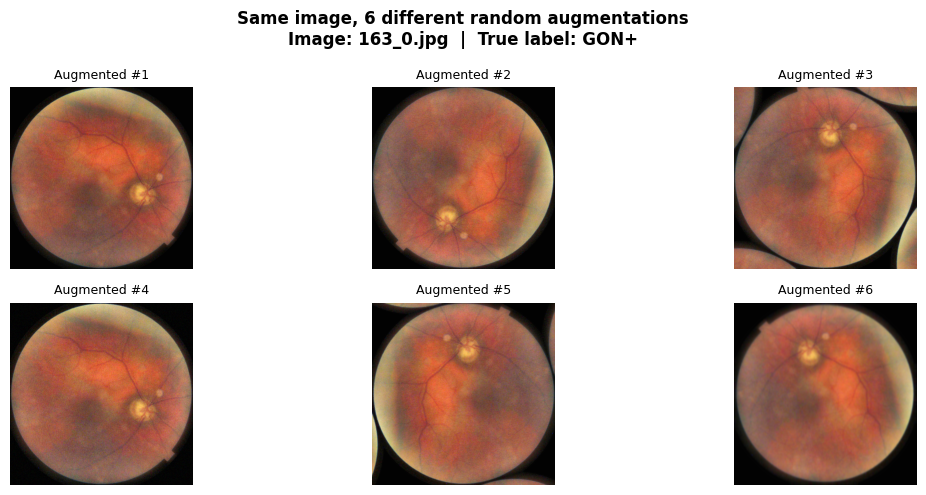

In [28]:
# visualise augmentations (training)
# run this cell multiple time, each time model see a different image even when the input image is same
sample_path = str(df["image_path"].sample(1).iloc[0])
sample_label = cfg.CLASS_NAMES[int(df["label"].iloc[0])]
tfm_train = get_transforms("train")

n_aug = 6
fig, axes = plt.subplots(2, n_aug // 2, figsize=(12, 5))
axes = axes.flatten()

for i, ax in enumerate(axes):
    item = {"image": sample_path, "label": 0}
    aug_tensor = tfm_train(item)["image"]

    mean = torch.tensor([0.485, 0.456, 0.406])[:, None, None]
    std = torch.tensor([0.229, 0.224, 0.225])[:, None, None]
    img_display = (aug_tensor * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()

    ax.imshow(img_display)
    ax.set_title(f"Augmented #{i + 1}", fontsize=9)
    ax.axis("off")

fig.suptitle(
    f"Same image, 6 different random augmentations\n"
    f"Image: {Path(sample_path).name}  |  True label: {sample_label}",
    fontweight="bold",
)
plt.tight_layout()
plt.show()


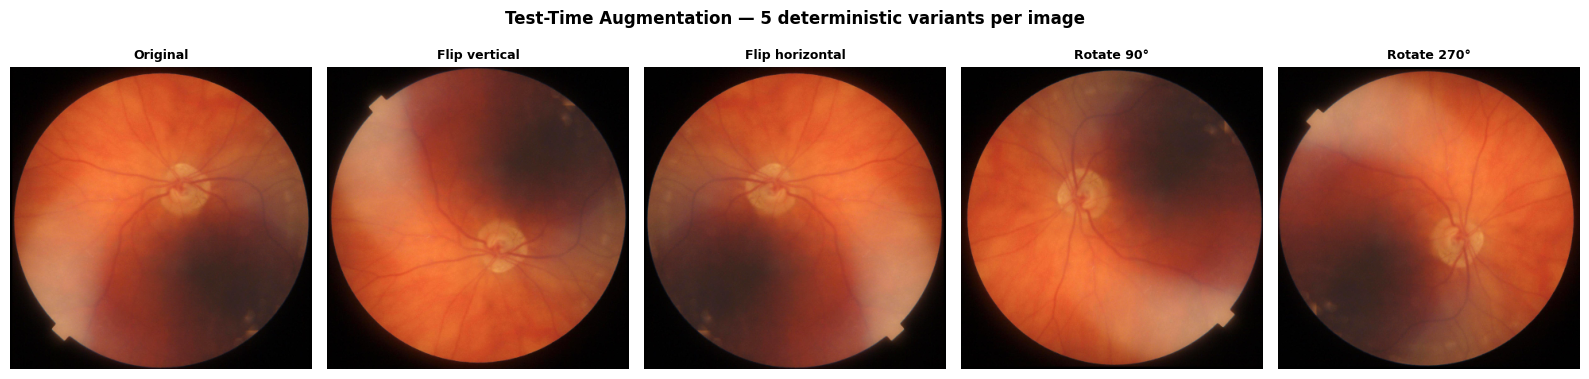

In [103]:
# visualise 5 TTA variants
tta_tfms = get_tta_transforms()
tta_names = [
    "Original",
    "Flip vertical",
    "Flip horizontal",
    "Rotate 90°",
    "Rotate 270°",
]

fig, axes = plt.subplots(1, 5, figsize=(16, 4))
mean = torch.tensor([0.485, 0.456, 0.406])[:, None, None]
std = torch.tensor([0.229, 0.224, 0.225])[:, None, None]

for ax, tfm, name in zip(axes, tta_tfms, tta_names):
    item = {"image": sample_path, "label": 0}
    t = tfm(item)["image"]
    img_display = (t * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()
    ax.imshow(img_display)
    ax.set_title(name, fontsize=9, fontweight="bold")
    ax.axis("off")

fig.suptitle(
    "Test-Time Augmentation — 5 deterministic variants per image", fontweight="bold"
)
plt.tight_layout()
plt.show()


# Data loader


In [104]:
def make_loader(
    df: pd.DataFrame, transform: Compose, mode: str, sampler=None
) -> DataLoader:
    data_list = df_to_monai_list(df)
    cache = cfg.CACHE_RATE if mode != "train" else 0.0

    dataset = CacheDataset(
        data=data_list,
        transform=transform,
        cache_rate=cache,
        num_workers=cfg.NUM_WORKERS,
        copy_cache=False,
    )
    return DataLoader(
        dataset,
        batch_size=cfg.BATCH_SIZE,
        shuffle=(mode == "train" and sampler is None),
        sampler=sampler,
        num_workers=cfg.NUM_WORKERS,
        pin_memory=(DEVICE.type == "cuda"),
        drop_last=(mode == "train"),
    )


def make_weighted_sampler(df: pd.DataFrame) -> WeightedRandomSampler:
    counts = df["label"].value_counts().to_dict()
    total = len(df)
    weights = df["label"].map(lambda x: total / counts[x]).values
    return WeightedRandomSampler(
        weights=torch.DoubleTensor(weights),
        num_samples=total,
        replacement=True,
    )


# test running: create a loader and pull one batch
val_loader = make_loader(val_df, get_transforms("val"), mode="val")
batch = next(iter(val_loader))

print(f"Batch image shape: {batch['image'].shape} (batch x channels x H x W)")
print(f"Batch label shape: {batch['label'].shape}")
print(f"Labels in batch: {batch['label'].tolist()}")
print(f"\nTotal val batches: {len(val_loader)}")
print(f"Total val images: {len(val_loader.dataset)}")


Loading dataset: 100%|██████████| 124/124 [00:07<00:00, 16.06it/s]


Batch image shape: torch.Size([16, 3, 380, 380]) (batch x channels x H x W)
Batch label shape: torch.Size([16])
Labels in batch: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]

Total val batches: 8
Total val images: 124


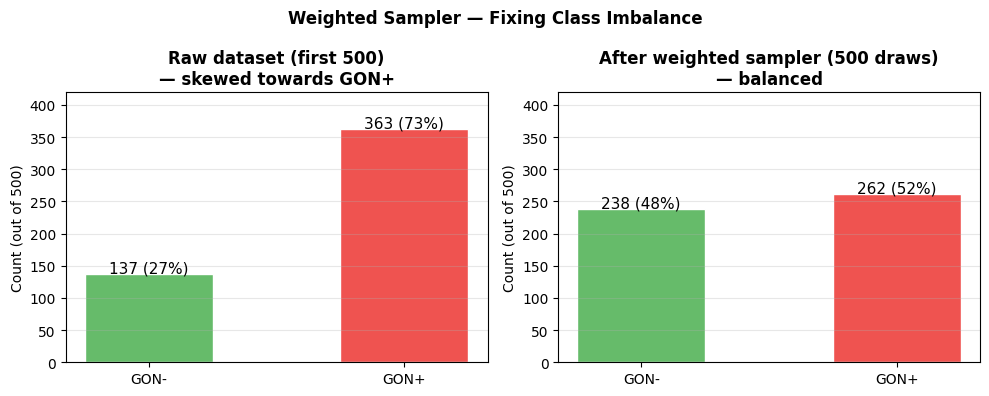

In [105]:
# visualise the weighted sampler effect
sampler = make_weighted_sampler(train_df)
sampled_indices = list(sampler)[:500]
sampled_labels  = [int(train_df["label"].iloc[i % len(train_df)]) for i in sampled_indices]

raw_labels = train_df["label"].values[:500]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, labels, title in [
    (axes[0], raw_labels,    "Raw dataset (first 500)\n— skewed towards GON+"),
    (axes[1], sampled_labels, "After weighted sampler (500 draws)\n— balanced"),
]:
    unique, cnts = np.unique(labels, return_counts=True)
    bar_labels = [cfg.CLASS_NAMES[u] for u in unique]
    bars = ax.bar(bar_labels, cnts, color=["#66BB6A", "#EF5350"], edgecolor="white", width=0.5)
    for bar, cnt in zip(bars, cnts):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2,
                f"{cnt} ({cnt/500*100:.0f}%)", ha="center", fontsize=11)
    ax.set_title(title, fontweight="bold")
    ax.set_ylabel("Count (out of 500)")
    ax.grid(axis="y", alpha=0.3)
    ax.set_ylim(0, 420)

plt.suptitle("Weighted Sampler — Fixing Class Imbalance", fontweight="bold")
plt.tight_layout()
plt.show()

# MODEL


In [106]:
class GlaucomaModel(nn.Module):
    def __init__(
        self,
        backbone: str = cfg.BACKBONE,
        pretrained: bool = cfg.PRETRAINED,
        dropout: float = cfg.DROPOUT,
    ):
        super().__init__()
        self.backbone = timm.create_model(
            backbone,
            pretrained=pretrained,
            num_classes=0,
            global_pool="avg",
        )
        in_features = self.backbone.num_features

        self.classifier = nn.Sequential(
            nn.LayerNorm(in_features),
            nn.Dropout(dropout),
            nn.Linear(in_features, 256),
            nn.GELU(),
            nn.Dropout(dropout / 2),
            nn.Linear(256, 1),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.classifier(self.backbone(x)).squeeze(1)


# test run
model = GlaucomaModel().to(DEVICE)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Backbone: {cfg.BACKBONE}")
print(f"Backbone output: {model.backbone.num_features} features")
print(f"Total params: {total_params:,}")
print(f"Trainable params: {trainable_params:,}")
print(f"Model on device: {next(model.parameters()).device}")

Backbone: efficientnet_b3
Backbone output: 1536 features
Total params: 11,093,033
Trainable params: 11,093,033
Model on device: cpu


In [107]:
# 1 forward pass check
model.eval()
with torch.no_grad():
    dummy_input = torch.randn(4, 3, cfg.IMG_SIZE, cfg.IMG_SIZE).to(DEVICE)
    logits = model(dummy_input)
    probs = torch.sigmoid(logits)

print(f"Input shape: {dummy_input.shape}   (4 images x 3 channels x 380 x 380)")
print(f"Logits shape: {logits.shape} (one score per image)")
print(f"Probs shape: {probs.shape} (sigmoid converts to 0-1 probability)")
print(f"\nSample logits: {logits.tolist()}")
print(f"Sample probs: {[round(p, 4) for p in probs.tolist()]}")
print("\nNegative logit → prob < 0.5 → predicts GON-")
print("Positive logit → prob > 0.5 → predicts GON+")

Input shape: torch.Size([4, 3, 380, 380])   (4 images x 3 channels x 380 x 380)
Logits shape: torch.Size([4]) (one score per image)
Probs shape: torch.Size([4]) (sigmoid converts to 0-1 probability)

Sample logits: [0.17891988158226013, 0.23186427354812622, 0.23505663871765137, 0.11692562699317932]
Sample probs: [0.5446, 0.5577, 0.5585, 0.5292]

Negative logit → prob < 0.5 → predicts GON-
Positive logit → prob > 0.5 → predicts GON+


# Mixup

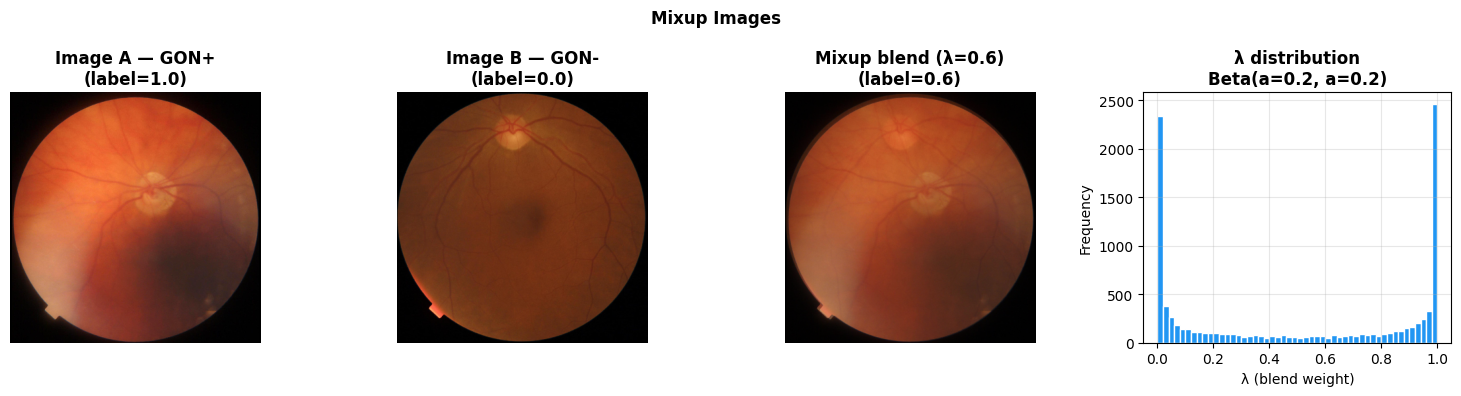

In [108]:
def mixup_data(x, y, alpha=cfg.MIXUP_ALPHA):
    lam = np.random.beta(alpha, alpha) if alpha > 0 else 1.0
    idx = torch.randperm(x.size(0), device=x.device)
    return lam * x + (1 - lam) * x[idx], y, y[idx], lam


def mixup_loss(criterion, pred, ya, yb, lam):
    return lam * criterion(pred, ya.float()) + (1 - lam) * criterion(pred, yb.float())


def tensor_to_display(t):
    return (t * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()


# ========================= visualise a mixup img =========================
tfm_v = get_transforms("val")
mean = torch.tensor([0.485, 0.456, 0.406])[:, None, None]
std = torch.tensor([0.229, 0.224, 0.225])[:, None, None]


# pick one GON+ and one GON- image
gon_pos_row = df[df["label"] == 1].iloc[0]
gon_neg_row = df[df["label"] == 0].iloc[0]
img_pos = tfm_v({"image": gon_pos_row["image_path"], "label": 1})["image"]
img_neg = tfm_v({"image": gon_neg_row["image_path"], "label": 0})["image"]

lam = 0.6
mixed = lam * img_pos + (1 - lam) * img_neg
mixed_label = lam * 1.0 + (1 - lam) * 0.0

fig, axes = plt.subplots(1, 4, figsize=(15, 4))
axes[0].imshow(tensor_to_display(img_pos))
axes[0].set_title("Image A — GON+\n(label=1.0)", fontweight="bold")
axes[1].imshow(tensor_to_display(img_neg))
axes[1].set_title("Image B — GON-\n(label=0.0)", fontweight="bold")
axes[2].imshow(tensor_to_display(mixed))
axes[2].set_title(
    f"Mixup blend (λ={lam})\n(label={mixed_label:.1f})", fontweight="bold"
)

# show λ distribution for MIXUP_ALPHA
lambdas = np.random.beta(cfg.MIXUP_ALPHA, cfg.MIXUP_ALPHA, 10000)
axes[3].hist(lambdas, bins=50, color="#2196F3", edgecolor="white")
axes[3].set_title(
    f"λ distribution\nBeta(a={cfg.MIXUP_ALPHA}, a={cfg.MIXUP_ALPHA})", fontweight="bold"
)
axes[3].set_xlabel("λ (blend weight)")
axes[3].set_ylabel("Frequency")
axes[3].grid(alpha=0.3)

for ax in axes[:3]:
    ax.axis("off")

plt.suptitle("Mixup Images", fontweight="bold")
plt.tight_layout()
plt.show()

# Training

Epoch 01 | val AUC = 0.7000 | (best)
Epoch 02 | val AUC = 0.7400 | (best)
Epoch 03 | val AUC = 0.7700 | (best)
Epoch 04 | val AUC = 0.7900 | (best)
Epoch 05 | val AUC = 0.8000 | (best)
Epoch 06 | val AUC = 0.7900 | no gain (1/8)
Epoch 07 | val AUC = 0.8100 | (best)
Epoch 08 | val AUC = 0.8000 | no gain (1/8)
Epoch 09 | val AUC = 0.7900 | no gain (2/8)
Epoch 10 | val AUC = 0.7900 | no gain (3/8)
Epoch 11 | val AUC = 0.7900 | no gain (4/8)
Epoch 12 | val AUC = 0.7900 | no gain (5/8)
Epoch 13 | val AUC = 0.7900 | no gain (6/8)
Epoch 14 | val AUC = 0.7900 | no gain (7/8)
Epoch 15 | val AUC = 0.7900 | no gain (8/8)

[EARLY STOP] Triggered at epoch 15


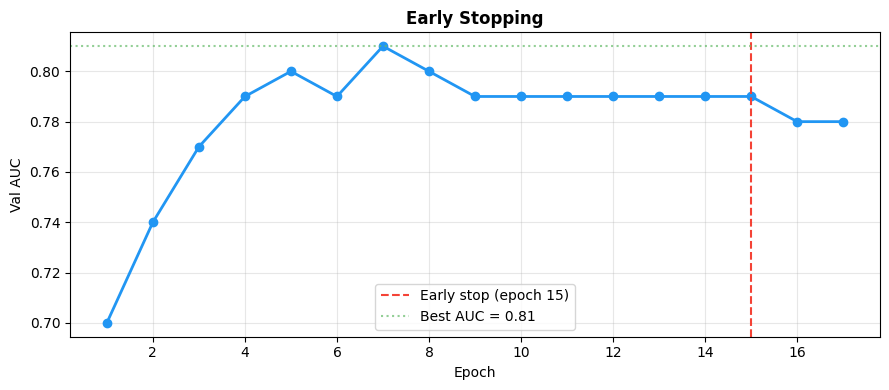

In [109]:
class EarlyStopping:
    def __init__(self, patience=cfg.EARLY_STOP, min_delta=1e-4):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.best = None
        self.stop = False

    def __call__(self, score: float) -> bool:
        if self.best is None or score > self.best + self.min_delta:
            self.best = score
            self.counter = 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.stop = True
        return self.stop


# simulate early stopping
mock_aucs = [
    0.70,
    0.74,
    0.77,
    0.79,
    0.80,
    0.79,
    0.81,
    0.80,
    0.79,
    0.79,
    0.79,
    0.79,
    0.79,
    0.79,
    0.79,
    0.78,
    0.78,
]
stopper = EarlyStopping(patience=cfg.EARLY_STOP)
stop_epoch = None

for epoch, auc in enumerate(mock_aucs, 1):
    stopped = stopper(auc)
    status = (
        "(best)"
        if stopper.counter == 0 and stopper.best == auc
        else f"no gain ({stopper.counter}/{stopper.patience})"
    )
    print(f"Epoch {epoch:02d} | val AUC = {auc:.4f} | {status}")
    if stopped:
        stop_epoch = epoch
        print(f"\n[EARLY STOP] Triggered at epoch {epoch}")
        break

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(range(1, len(mock_aucs) + 1), mock_aucs, "o-", color="#2196F3", linewidth=2)
if stop_epoch:
    ax.axvline(
        stop_epoch,
        color="#F44336",
        linestyle="--",
        label=f"Early stop (epoch {stop_epoch})",
    )
ax.axhline(
    max(mock_aucs),
    color="#66BB6A",
    linestyle=":",
    alpha=0.7,
    label=f"Best AUC = {max(mock_aucs)}",
)
ax.set_title("Early Stopping", fontweight="bold")
ax.set_xlabel("Epoch")
ax.set_ylabel("Val AUC")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [110]:
def train_one_epoch(model: GlaucomaModel, loader, optimizer, criterion) -> Dict:
    model.train()
    total_loss, all_probs, all_labels = 0.0, [], []

    for batch in tqdm(loader, desc="Train", leave=False):
        imgs = batch["image"].to(DEVICE)
        labels = batch["label"].to(DEVICE)

        if cfg.USE_MIXUP:
            imgs, ya, yb, lam = mixup_data(imgs, labels)

        logits = model(imgs)
        loss = (
            mixup_loss(criterion, logits, ya, yb, lam)
            if cfg.USE_MIXUP
            else criterion(logits, labels.float())
        )

        optimizer.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()

        total_loss += loss.item() * imgs.size(0)
        all_probs.extend(torch.sigmoid(logits).detach().cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    preds_bin = (np.array(all_probs) >= 0.5).astype(int)
    return {
        "loss": total_loss / len(loader.dataset),
        "auc": roc_auc_score(all_labels, all_probs),
        "acc": accuracy_score(all_labels, preds_bin),
    }


@torch.no_grad()
def evaluate(model: GlaucomaModel, loader, criterion) -> Dict:
    model.eval()
    total_loss, all_probs, all_labels = 0.0, [], []

    for batch in tqdm(loader, desc="Eval", leave=False):
        imgs = batch["image"].to(DEVICE)
        labels = batch["label"].to(DEVICE)
        logits = model(imgs)
        loss = criterion(logits, labels.float())

        total_loss += loss.item() * imgs.size(0)
        all_probs.extend(torch.sigmoid(logits).cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    preds_bin = (np.array(all_probs) >= 0.5).astype(int)
    return {
        "loss": total_loss / len(loader.dataset),
        "auc": roc_auc_score(all_labels, all_probs),
        "acc": accuracy_score(all_labels, preds_bin),
        "f1": f1_score(all_labels, preds_bin),
        "preds": np.array(all_probs),
        "labels": np.array(all_labels),
    }


def train(train_df, val_df, fold=None) -> GlaucomaModel:
    tag = f"fold{fold}" if fold is not None else "model"
    ckpt_path = cfg.OUTPUT_DIR / f"best_{tag}.pt"

    sampler = make_weighted_sampler(train_df)
    train_loader = make_loader(
        train_df, get_transforms("train"), mode="train", sampler=sampler
    )
    val_loader = make_loader(val_df, get_transforms("val"), mode="val")

    model = GlaucomaModel().to(DEVICE)
    criterion = nn.BCEWithLogitsLoss(
        pos_weight=torch.tensor(
            [(train_df["label"] == 0).sum() / max((train_df["label"] == 1).sum(), 1)],
            device=DEVICE,
        )
    )
    optimizer = optim.AdamW(
        model.parameters(), lr=cfg.LR, weight_decay=cfg.WEIGHT_DECAY
    )
    scheduler = optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=cfg.EPOCHS, eta_min=1e-6
    )
    stopper = EarlyStopping()
    best_auc = 0.0
    history = {"train_loss": [], "val_loss": [], "train_auc": [], "val_auc": []}

    print(f"\n{'=' * 60}\n  {tag.upper()}  —  {cfg.BACKBONE}\n{'=' * 60}")

    for epoch in range(1, cfg.EPOCHS + 1):
        tr = train_one_epoch(model, train_loader, optimizer, criterion)
        vl = evaluate(model, val_loader, criterion)
        scheduler.step()

        history["train_loss"].append(tr["loss"])
        history["val_loss"].append(vl["loss"])
        history["train_auc"].append(tr["auc"])
        history["val_auc"].append(vl["auc"])

        flag = ""
        if vl["auc"] > best_auc:
            best_auc = vl["auc"]
            torch.save(model.state_dict(), ckpt_path)
            flag = "  ← best"

        print(
            f"  Ep {epoch:03d}/{cfg.EPOCHS} "
            f"| Loss {tr['loss']:.4f}/{vl['loss']:.4f} "
            f"| AUC {tr['auc']:.4f}/{vl['auc']:.4f} "
            f"| Acc {tr['acc']:.4f}/{vl['acc']:.4f}{flag}"
        )

        if stopper(vl["auc"]):
            print(f"  [EARLY STOP] No gain for {cfg.EARLY_STOP} epochs.")
            break

    model.load_state_dict(torch.load(ckpt_path, map_location=DEVICE))
    return model, history

In [123]:
# TRAIN
# model, history = train(train_df, val_df)

# load trained
model = GlaucomaModel()
model.load_state_dict(
    state_dict=torch.load(cfg.OUTPUT_DIR / "best_model.pt", map_location=DEVICE)
)

<All keys matched successfully>

---
## 11 · Training Curves (`plot_training_curves`)

After training, we plot loss and AUC over epochs.  
These curves tell us:
- **Underfitting**: both train and val scores are poor — model is too simple or not trained long enough
- **Overfitting**: train score is high, val score diverges downward — model memorised training data
- **Good fit**: both scores improve together and val plateaus at a high value


In [125]:
def plot_training_curves(history: Dict, tag: str):
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    ep = range(1, len(history["train_loss"]) + 1)

    for ax, tr_k, vl_k, title, ylabel in [
        (axes[0], "train_loss", "val_loss", "Loss", "Loss"),
        (axes[1], "train_auc", "val_auc", "AUC-ROC", "AUC"),
    ]:
        ax.plot(
            ep,
            history[tr_k],
            "o-",
            label="Train",
            color="#2196F3",
            linewidth=2,
            markersize=4,
        )
        ax.plot(
            ep,
            history[vl_k],
            "o-",
            label="Val",
            color="#F44336",
            linewidth=2,
            markersize=4,
        )

        # mark best val epoch
        if "auc" in vl_k:
            best_ep = int(np.argmax(history[vl_k])) + 1
            best_v = max(history[vl_k])
            ax.scatter(
                [best_ep],
                [best_v],
                color="#FF9800",
                s=120,
                zorder=5,
                label=f"Best (ep {best_ep}, {best_v:.4f})",
            )

        ax.set_title(title, fontweight="bold")
        ax.set_xlabel("Epoch")
        ax.set_ylabel(ylabel)
        ax.legend()
        ax.grid(True, alpha=0.3)

    plt.suptitle(f"Training Curves {tag}", fontweight="bold", fontsize=13)
    plt.tight_layout()
    plt.show()

# TTA prediction

In [126]:
@torch.no_grad()
def tta_predict(model: GlaucomaModel, df: pd.DataFrame) -> np.ndarray:
    model.eval()
    tta_tfms = get_tta_transforms()[: cfg.TTA_STEPS]
    all_probs = []

    for tfm in tqdm(tta_tfms, desc="TTA"):
        loader = make_loader(df, tfm, mode="test")
        probs = []
        for batch in loader:
            logits = model(batch["image"].to(DEVICE))
            probs.extend(torch.sigmoid(logits).cpu().numpy())
        all_probs.append(np.array(probs))

    return np.mean(all_probs, axis=0)


def find_optimal_threshold(labels: np.ndarray, probs: np.ndarray) -> float:
    fpr, tpr, thresholds = roc_curve(labels, probs)
    return float(thresholds[np.argmax(tpr - fpr)])


def full_evaluation(labels, probs, split="Test") -> Tuple[Dict, np.ndarray, np.ndarray]:
    threshold = find_optimal_threshold(labels, probs)
    preds = (probs >= threshold).astype(int)
    cm = confusion_matrix(labels, preds)
    tn, fp, fn, tp = cm.ravel()

    metrics = {
        "AUC-ROC": roc_auc_score(labels, probs),
        "Accuracy": accuracy_score(labels, preds),
        "F1 (macro)": f1_score(labels, preds, average="macro"),
        "Sensitivity": tp / (tp + fn),
        "Specificity": tn / (tn + fp),
        "PPV": tp / (tp + fp),
        "NPV": tn / (tn + fn),
        "Threshold": threshold,
    }

    print(f"\n{'=' * 50}\n  {split} Results(threshold = {threshold:.3f})\n{'=' * 52}")
    for k, v in metrics.items():
        print(f"  {k:<14}: {v:.4f}")
    print(f"\n  Confusion Matrix:\n{cm}")
    print(f"\n{classification_report(labels, preds, target_names=cfg.CLASS_NAMES)}")
    return metrics, preds, cm


# test running
print("[INFERENCE] Running TTA on test set...")
probs = tta_predict(model, test_df)
labels = test_df["label"].values

metrics, preds, cm = full_evaluation(labels, probs)

[INFERENCE] Running TTA on test set...


TTA:   0%|          | 0/5 [00:00<?, ?it/s]

Loading dataset: 100%|██████████| 121/121 [00:07<00:00, 15.97it/s]



  Test Results(threshold = 0.449)
  AUC-ROC       : 0.9993
  Accuracy      : 0.9835
  F1 (macro)    : 0.9778
  Sensitivity   : 0.9783
  Specificity   : 1.0000
  PPV           : 1.0000
  NPV           : 0.9355
  Threshold     : 0.4487

  Confusion Matrix:
[[29  0]
 [ 2 90]]

              precision    recall  f1-score   support

        GON-       0.94      1.00      0.97        29
        GON+       1.00      0.98      0.99        92

    accuracy                           0.98       121
   macro avg       0.97      0.99      0.98       121
weighted avg       0.98      0.98      0.98       121



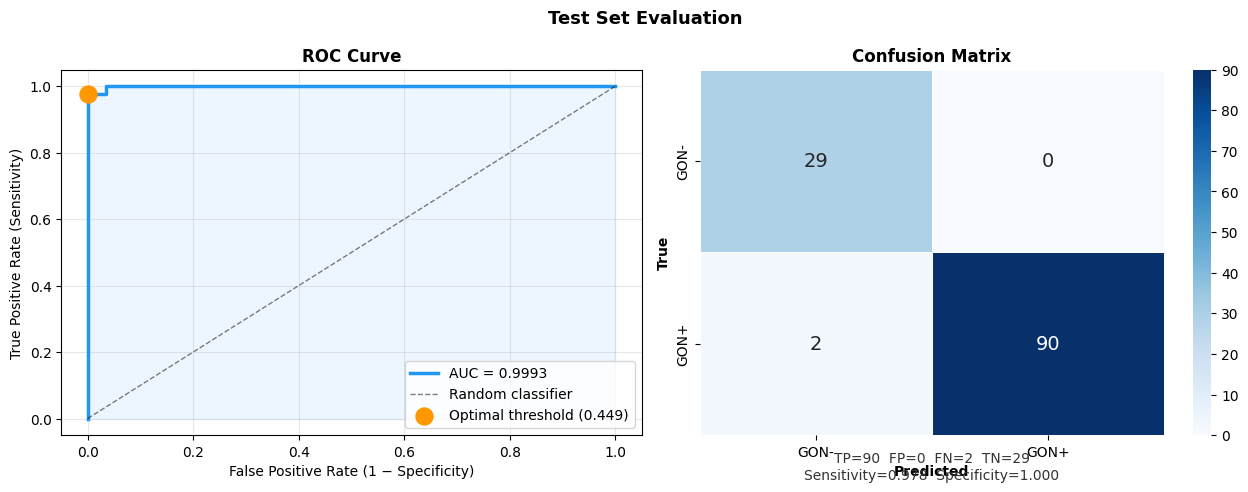

In [127]:
# ROC curve
fpr, tpr, thresholds = roc_curve(labels, probs)
auc = roc_auc_score(labels, probs)
opt_thr = find_optimal_threshold(labels, probs)
opt_idx = np.argmin(np.abs(thresholds - opt_thr))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# left - ROC curve
axes[0].plot(fpr, tpr, color="#2196F3", lw=2.5, label=f"AUC = {auc:.4f}")
axes[0].plot([0, 1], [0, 1], "k--", lw=1, alpha=0.5, label="Random classifier")
axes[0].fill_between(fpr, tpr, alpha=0.08, color="#2196F3")
axes[0].scatter(
    [fpr[opt_idx]],
    [tpr[opt_idx]],
    color="#FF9800",
    s=150,
    zorder=5,
    label=f"Optimal threshold ({opt_thr:.3f})",
)
axes[0].set_xlabel("False Positive Rate (1 − Specificity)")
axes[0].set_ylabel("True Positive Rate (Sensitivity)")
axes[0].set_title("ROC Curve", fontweight="bold")
axes[0].legend(loc="lower right")
axes[0].grid(alpha=0.3)

# right - confusion matrix
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=cfg.CLASS_NAMES,
    yticklabels=cfg.CLASS_NAMES,
    ax=axes[1],
    linewidths=0.5,
    annot_kws={"size": 14},
)
axes[1].set_xlabel("Predicted", fontweight="bold")
axes[1].set_ylabel("True", fontweight="bold")
axes[1].set_title("Confusion Matrix", fontweight="bold")

tn, fp, fn, tp = cm.ravel()
axes[1].text(
    0.5,
    -0.12,
    f"TP={tp}  FP={fp}  FN={fn}  TN={tn}\n"
    f"Sensitivity={tp / (tp + fn):.3f}  Specificity={tn / (tn + fp):.3f}",
    ha="center",
    transform=axes[1].transAxes,
    fontsize=10,
    color="#333",
)

plt.suptitle("Test Set Evaluation", fontweight="bold", fontsize=13)
plt.tight_layout()
plt.show()

# XAI - Grad-CAM++

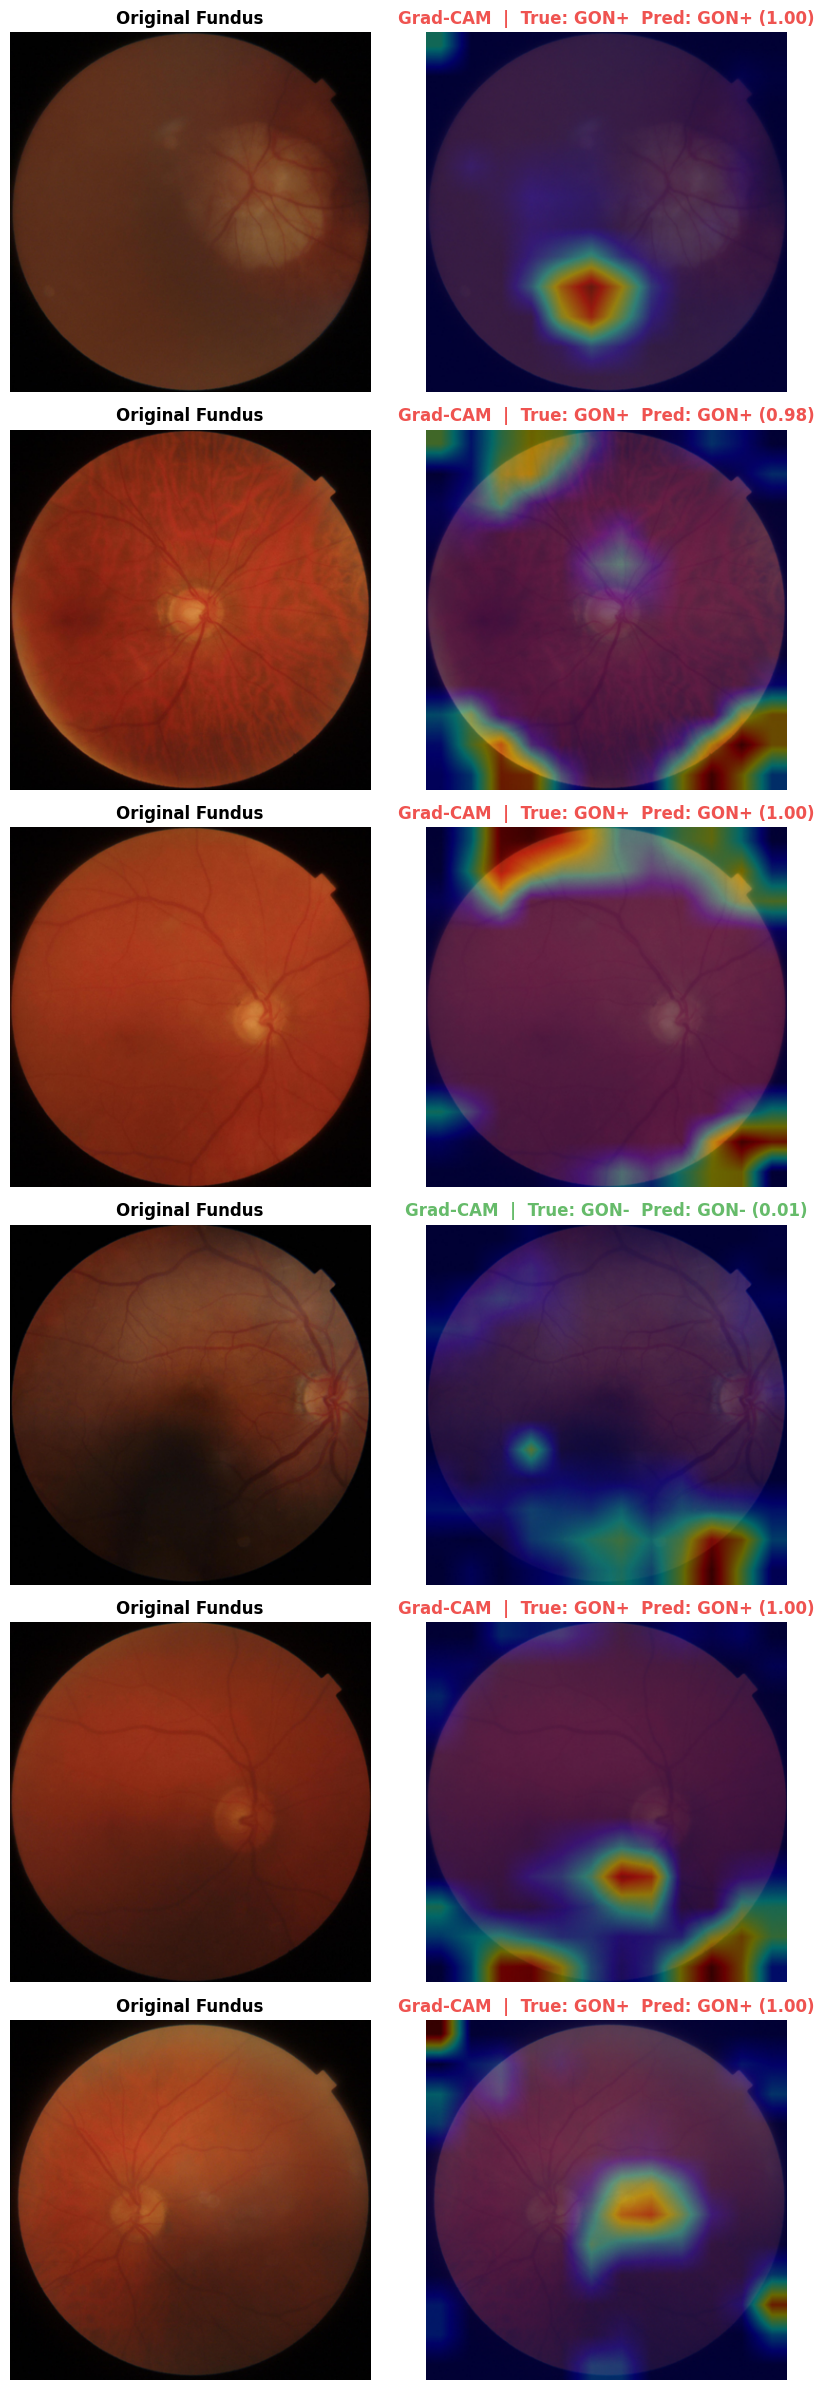

In [147]:
def visualise_gradcam(model: GlaucomaModel, df: pd.DataFrame):
    tfm = get_transforms("val")
    n = len(df)
    saved = 0
    rows_to_show = []

    # ── identify the target layer (last conv block, still has spatial dims) ──
    target_layer = model.backbone.blocks[-1]

    # storage for hook outputs
    _activations = {}
    _gradients = {}

    def forward_hook(module, input, output):
        _activations["value"] = output.detach()  # shape: (1, C, H', W')

    def backward_hook(module, grad_in, grad_out):
        _gradients["value"] = grad_out[0].detach()  # shape: (1, C, H', W')

    fwd_handle = target_layer.register_forward_hook(forward_hook)
    bwd_handle = target_layer.register_full_backward_hook(backward_hook)

    try:
        for _, row in df.iterrows():
            if saved >= n:
                break

            item = {"image": row["image_path"], "label": int(row["label"])}
            tensor = tfm(item)["image"].unsqueeze(0).to(DEVICE)

            # ── forward + backward to populate hooks ─────────────────────────
            model.zero_grad()
            logit = model(tensor)  # triggers forward hook
            logit.backward()  # triggers backward hook

            acts = _activations["value"]  # (1, C, H', W')
            grads = _gradients["value"]  # (1, C, H', W')

            # Grad-CAM: weight each channel map by its mean gradient
            weights = grads.mean(dim=(2, 3), keepdim=True)  # (1, C, 1, 1)
            cam = (weights * acts).sum(dim=1).squeeze(0)  # (H', W')
            cam = torch.clamp(cam, min=0)  # ReLU

            # normalise to [0, 1]
            cam -= cam.min()
            cam /= cam.max() + 1e-8
            saliency = cam.cpu().numpy()  # (H', W') — guaranteed 2-D

            # ── get prediction ───────────────────────────────────────────────
            prob = float(torch.sigmoid(logit).detach().cpu())
            pred_cls = cfg.CLASS_NAMES[int(prob >= 0.5)]
            true_cls = cfg.CLASS_NAMES[int(row["label"])]
            if pred_cls != true_cls:
                continue

            # ── build overlay ────────────────────────────────────────────────
            orig = np.array(
                Image.open(row["image_path"])
                .convert("RGB")
                .resize((cfg.IMG_SIZE, cfg.IMG_SIZE))
            )
            heat = cv2.resize(saliency, (cfg.IMG_SIZE, cfg.IMG_SIZE))
            heat = cv2.applyColorMap((heat * 255).astype(np.uint8), cv2.COLORMAP_JET)
            heat = cv2.cvtColor(heat, cv2.COLOR_BGR2RGB)
            overlay = cv2.addWeighted(orig, 0.6, heat, 0.4, 0)

            rows_to_show.append(
                (orig, overlay, true_cls, pred_cls, prob, row[cfg.IMAGE_COL])
            )
            saved += 1

    finally:
        # always remove hooks even if an exception occurs mid-loop
        fwd_handle.remove()
        bwd_handle.remove()

    if not rows_to_show:
        print("[WARN] No correctly-predicted samples found in sample.")
        return

    fig, axes = plt.subplots(len(rows_to_show), 2, figsize=(9, 4 * len(rows_to_show)))
    if len(rows_to_show) == 1:
        axes = [axes]

    for row_axes, (orig, overlay, true_cls, pred_cls, prob, fname) in zip(
        axes, rows_to_show
    ):
        row_axes[0].imshow(orig)
        row_axes[0].set_title("Original Fundus", fontweight="bold")
        row_axes[0].axis("off")

        row_axes[1].imshow(overlay)
        row_axes[1].set_title(
            f"Grad-CAM  |  True: {true_cls}  Pred: {pred_cls} ({prob:.2f})",
            fontweight="bold",
            color="#EF5350" if true_cls == "GON+" else "#66BB6A",
        )
        row_axes[1].axis("off")

    plt.tight_layout()
    plt.show()


df_xai = df.sample(6)
visualise_gradcam(model, df_xai)